---
title: "Self-study Lab 10: A Closer Look at the Logistic Cost Function"
subtitle: "Machine Learning, Lecture 4: Logistic regression"
author: "Khiem Nguyen"
format:
  html:
    toc: true
    toc-depth: 3
    embed-resources: true
    code-overflow: wrap
    fig-align: center
jupyter: python3
---

## Objectives

Lab 8 used the logistic cost to train the model. In this lab you will study the cost itself:

- understand the logistic loss and why it punishes confident mistakes;
- see why the squared error is a bad cost for logistic regression;
- compute the cost without taking the logarithm of zero;
- see that on perfectly separable data the cost has **no minimum**, and what this means for gradient descent and scikit-learn.

## Tools

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression

np.set_printoptions(precision=3, suppress=True)   # print arrays with 3 decimals, no e-notation

def sigmoid(z):
    """Sigmoid function g(z) = 1 / (1 + exp(-z)), element by element."""
    return 1.0 / (1.0 + np.exp(-z))

## The logistic loss

For one example with prediction $f = f_{\mathbf w,b}(\mathbf x)$ and label $y$, the logistic loss is
$$
L(f, y) = \begin{cases} -\log(f) & \text{if } y = 1,\\ -\log(1 - f) & \text{if } y = 0,\end{cases}
\qquad\text{or in one formula}\qquad
L(f, y) = -y\log(f) - (1 - y)\log(1 - f),
$$
and the cost $J(\mathbf w, b)$ is the average loss over the training set. In the single formula one of the two terms is always zero: for $y = 1$ only $-\log(f)$ remains, for $y = 0$ only $-\log(1 - f)$.

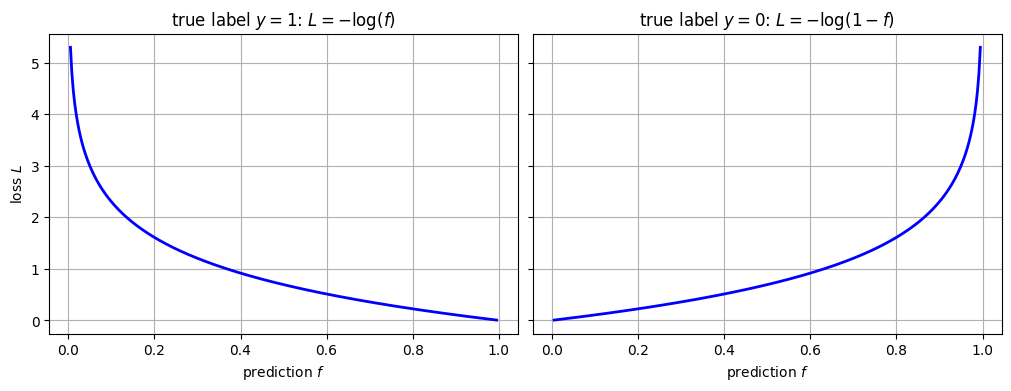

In [2]:
f = np.linspace(0.005, 0.995, 300)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True, constrained_layout=True)
ax[0].plot(f, -np.log(f), 'b-', lw=2)
ax[0].set(xlabel='prediction $f$', ylabel='loss $L$', title='true label $y = 1$: $L = -\\log(f)$')
ax[1].plot(f, -np.log(1 - f), 'b-', lw=2)
ax[1].set(xlabel='prediction $f$', title='true label $y = 0$: $L = -\\log(1 - f)$')
for a in ax:
    a.grid(True)
plt.show()

The loss is $0$ when the model predicts the true label with full confidence and grows without bound when it is confident **and wrong**: for $y = 1$, $f = 0.9$ costs $0.11$, $f = 0.5$ costs $\log 2 = 0.69$ and $f = 0.01$ costs $4.6$.

::: {.callout-note collapse="true" title="Where does the logistic loss come from? (optional)"}
The model states $P(y = 1 \mid \mathbf x) = f$ and $P(y = 0 \mid \mathbf x) = 1 - f$, or in one formula $P(y \mid \mathbf x) = f^{\,y}(1 - f)^{1 - y}$. Each loss is $-\log$ of the probability that the model gives to the **true** label. For independent examples, the probability of all observed labels (the **likelihood**) is the product $\prod_i P(y^{(i)} \mid \mathbf x^{(i)})$, and
$$
-\frac1m\log\prod_{i=1}^{m} P\big(y^{(i)} \mid \mathbf x^{(i)}\big) = J(\mathbf w, b).
$$
So minimising $J$ is the same as maximising the likelihood (**maximum likelihood estimation**).
:::

## Why not the squared error?

With the sigmoid inside $f$, the squared-error cost $\frac{1}{2m}\sum_i\big(f_{w,b}(x^{(i)}) - y^{(i)}\big)^2$ is no longer a convex bowl. We evaluate both costs on a grid of $(w, b)$ values for the lecture's small 1D data set, whose classes overlap.

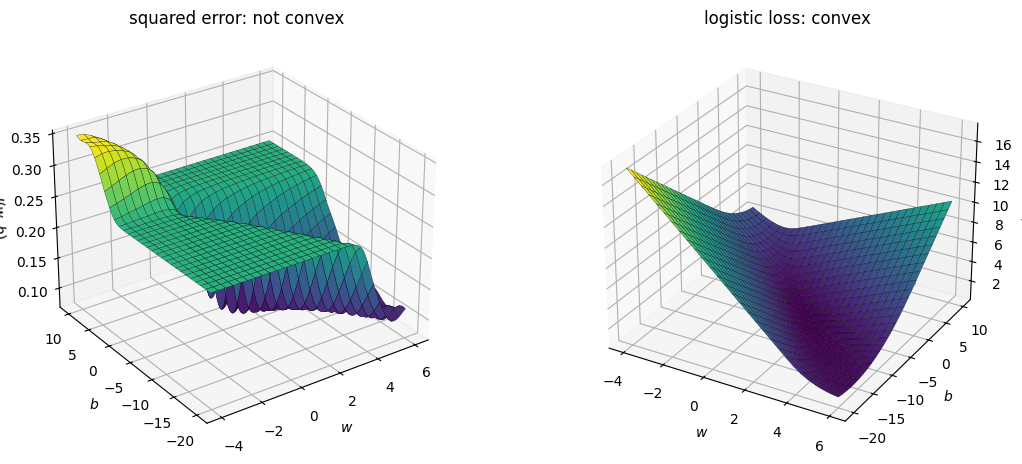

In [3]:
x_c = np.array([0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0])
y_c = np.array([0, 0, 0, 1, 0, 1, 0, 1, 1, 1])

def loss_from_z(z, y):
    """Logistic loss computed from z = w x + b (see the next section)."""
    return y * np.logaddexp(0, -z) + (1 - y) * np.logaddexp(0, z)

W, B = np.meshgrid(np.linspace(-4, 6, 141), np.linspace(-20, 10, 141))
Z = W[..., None] * x_c + B[..., None]        # shape (141, 141, 10): z for every (w, b) and every example
J_sq = np.mean((sigmoid(Z) - y_c) ** 2, axis=-1) / 2
J_log = np.mean(loss_from_z(Z, y_c), axis=-1)

fig = plt.figure(figsize=(11, 4.5), constrained_layout=True)
for k, (J, title, view) in enumerate([(J_sq, 'squared error: not convex', -125),
                                      (J_log, 'logistic loss: convex', -60)]):
    ax = fig.add_subplot(1, 2, k + 1, projection='3d')
    ax.plot_surface(W, B, J, cmap='viridis', rstride=5, cstride=5, edgecolor='k', lw=0.2)
    ax.view_init(28, view)
    ax.set(xlabel='$w$', ylabel='$b$', zlabel='$J(w, b)$', title=title)
plt.show()

`W[..., None]` adds a new last axis, so that broadcasting combines every grid point $(w, b)$ with every example $x^{(i)}$; the mean over the last axis averages over the examples. This replaces a double loop over the grid.

The squared-error cost has large **flat plateaus** where the sigmoid saturates: there the gradient is almost zero and gradient descent stalls. Such a cost can also have local minima. The logistic cost is **convex**, so gradient descent cannot get stuck. On these data it has a unique minimum, which gradient descent and scikit-learn both find:

In [4]:
w, b = 0.0, 0.0
for _ in range(20_000):                       # gradient descent, alpha = 0.5
    err = sigmoid(w * x_c + b) - y_c
    w, b = w - 0.5 * np.mean(err * x_c), b - 0.5 * np.mean(err)
sk = LogisticRegression(C=1e10).fit(x_c.reshape(-1, 1), y_c)    # C=1e10: no regularisation
print(f"gradient descent: w = {w:.3f}, b = {b:.3f}")
print(f"scikit-learn:     w = {sk.coef_[0, 0]:.3f}, b = {sk.intercept_[0]:.3f}")

gradient descent: w = 1.353, b = -3.722
scikit-learn:     w = 1.354, b = -3.723


## Computing the cost safely

In exact arithmetic $0 < f < 1$. In floating point, however, $g(z)$ is rounded to exactly $1.0$ once $z$ is larger than about $37$, and then $\log(1 - f) = \log(0) = -\infty$. We use the data of this lab, with a far-away malignant tumour at $x = 20$, and the parameters $w = 10$, $b = -25$:

In [5]:
x_train = np.array([0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 20.0])
y_train = np.array([0, 0, 0, 1, 1, 1, 1])

f = sigmoid(10 * x_train - 25)
with np.printoptions(precision=2, suppress=False):     # scientific notation for tiny numbers
    print(f"1 - f = {1 - f}")
losses = -y_train * np.log(f) - (1 - y_train) * np.log(1 - f)     # NumPy warns
print(f"losses: {losses}")

1 - f = [1.00e+00 1.00e+00 9.93e-01 6.69e-03 3.06e-07 1.39e-11 0.00e+00]
losses: [0.    0.    0.007 0.007 0.    0.      nan]


/tmp/ipykernel_878/3737506428.py:7: RuntimeWarning: divide by zero encountered in log
  losses = -y_train * np.log(f) - (1 - y_train) * np.log(1 - f)     # NumPy warns
/tmp/ipykernel_878/3737506428.py:7: RuntimeWarning: invalid value encountered in multiply
  losses = -y_train * np.log(f) - (1 - y_train) * np.log(1 - f)     # NumPy warns


For the last example $1 - f$ is exactly $0$. Its true loss is tiny, but the formula computes $0\cdot\log(0) = 0\cdot(-\infty)$, which is undefined (`nan`), so the cost becomes `nan` as well. NumPy also prints two `RuntimeWarning`s. Large values of $z$ occur easily, e.g. for unscaled features or during training on separable data.

The cure is to compute the loss directly from $z$. Since $-\log g(z) = \log(1 + e^{-z})$ and $-\log\big(1 - g(z)\big) = \log(1 + e^{z})$,
$$
L = y\log\big(1 + e^{-z}\big) + (1 - y)\log\big(1 + e^{z}\big),
$$
and `np.logaddexp(0, t)` computes $\log(1 + e^{t})$ without overflow. This is the function `loss_from_z` defined above; scikit-learn and PyTorch use the same idea internally.

In [6]:
print(f"stable losses: {loss_from_z(10 * x_train - 25, y_train)}")
print(f"cost J(10, -25) = {np.mean(loss_from_z(10 * x_train - 25, y_train)):.6f}")

stable losses: [0.    0.    0.007 0.007 0.    0.    0.   ]
cost J(10, -25) = 0.001919


Symbolic computation, e.g. with SymPy, is not needed: the stable formula is exact and fast.

## Perfectly separable data: no minimum

The data above are **perfectly separable**: every point left of $x = 2.5$ has $y = 0$, every point right of it $y = 1$.

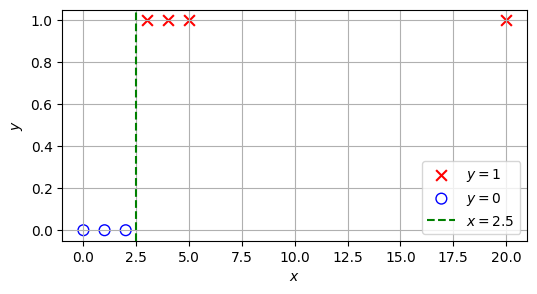

In [7]:
plt.figure(figsize=(6, 3))
plt.scatter(x_train[y_train == 1], y_train[y_train == 1], marker='x', c='r', s=60, label='$y = 1$')
plt.scatter(x_train[y_train == 0], y_train[y_train == 0], marker='o', facecolor='none', edgecolor='b', s=60, label='$y = 0$')
plt.axvline(2.5, color='g', ls='--', label='$x = 2.5$')
plt.xlabel('$x$')
plt.ylabel('$y$')
plt.legend()
plt.grid(True)
plt.show()

Take the parameters $(w, b) = t\,(1, -2.5)$ for growing $t > 0$. The boundary $wx + b = 0$ stays at $x = 2.5$, but the sigmoid gets steeper, every prediction moves towards its correct label, and the cost decreases:

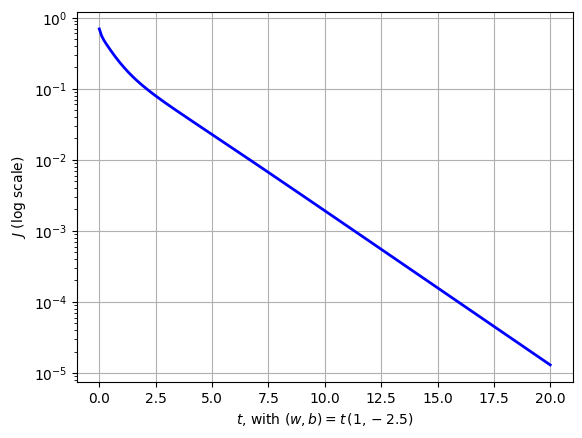

In [8]:
t_values = np.linspace(0, 20, 201)
J_ray = [np.mean(loss_from_z(t * (x_train - 2.5), y_train)) for t in t_values]
plt.semilogy(t_values, J_ray, 'b-', lw=2)
plt.xlabel('$t$, with $(w, b) = t\\,(1, -2.5)$')
plt.ylabel('$J$ (log scale)')
plt.grid(True)
plt.show()

$J$ approaches $0$ but never reaches it: there is **no minimum**. Gradient descent therefore never stops improving; the parameters keep growing, while the boundary settles:

In [9]:
def gradient_descent(x, y, alpha=0.5, n_iters=1000):
    """Gradient descent for logistic regression with one feature, from w = 0, b = 0."""
    w, b = 0.0, 0.0
    for _ in range(n_iters):
        err = sigmoid(w * x + b) - y
        w, b = w - alpha * np.mean(err * x), b - alpha * np.mean(err)
    return w, b

for n_iters in [1_000, 10_000, 100_000]:
    w, b = gradient_descent(x_train, y_train, n_iters=n_iters)
    J = np.mean(loss_from_z(w * x_train + b, y_train))
    print(f"{n_iters:7,d} iterations: w = {w:6.2f}, b = {b:7.2f}, J = {J:.1e}, boundary x = {-b / w:.3f}")

  1,000 iterations: w =   3.81, b =   -9.31, J = 4.1e-02, boundary x = 2.445
 10,000 iterations: w =   7.83, b =  -19.39, J = 5.7e-03, boundary x = 2.477


100,000 iterations: w =  12.42, b =  -30.88, J = 5.8e-04, boundary x = 2.486


scikit-learn behaves in the same way. Without regularisation its solver stops at some large $(w, b)$ once the gradient is tiny; with the default regularisation ($C = 1$) the weights stay small, and the minimum is unique (Lecture 5).

In [10]:
for C in [1e10, 1.0]:
    model = LogisticRegression(C=C, max_iter=1000).fit(x_train.reshape(-1, 1), y_train)
    w_sk, b_sk = model.coef_[0, 0], model.intercept_[0]
    print(f"scikit-learn, C = {C:g}: w = {w_sk:6.2f}, b = {b_sk:7.2f}, boundary x = {-b_sk / w_sk:.3f}")

scikit-learn, C = 1e+10: w =  15.41, b =  -38.21, boundary x = 2.479
scikit-learn, C = 1: w =   1.12, b =   -2.80, boundary x = 2.500


All boundaries lie near $x = 2.5$, but the parameters differ widely. On separable data, comparing parameters is meaningless; compare decision boundaries or predictions instead. This explains why gradient descent and scikit-learn "disagreed" on the separable toy example in Lab 8.

## Challenges

1. Show that $-\log g(z) = \log(1 + e^{-z})$ and $-\log\big(1 - g(z)\big) = \log(1 + e^{z})$.
2. Remove the point $x = 20$ and add a benign tumour at $x = 2.8$. Are the data still separable? Run gradient descent for $10^3$, $10^4$ and $10^5$ iterations: do the parameters still grow?
3. Plot $J_{\text{sq}}$ and $J_{\log}$ along the line $b = -3$ as functions of $w$ (one-dimensional slices of the two surfaces). Where is the squared-error cost flat?

## Summary

- The logistic loss is $-\log(\text{probability of the true label})$: zero for confident correct predictions, unbounded for confident wrong ones. Minimising the cost is maximum likelihood estimation.
- With the sigmoid inside $f$, the squared error gives a non-convex cost with flat plateaus; the logistic cost is convex.
- Compute the loss from $z$ with `np.logaddexp`, never as $\log(1 - g(z))$ for large $z$.
- On perfectly separable data the logistic cost has no minimum: the parameters grow without bound while the boundary settles. Regularisation (scikit-learn's default) makes the solution unique.